# ¿Qué tan grande se vuelve el brote? El tamaño final y por qué ignora el tiempo

**Pregunta:** ¿Qué parte de una población infecta un brote al final, por qué esa parte depende de $R_0$ y no de qué tan rápido corre el brote, y cuándo la corrida del propio motor no la alcanza?

- **Nivel:** 2, El método en la práctica
- **Requisitos:** notebook 01 de este tema
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este notebook puedes resolver la relación del tamaño final por iteración y ver cómo converge, ubicar las tasas de ataque que simula el motor sobre la curva de la relación, mostrar que dos brotes con el mismo $R_0$ y distinta velocidad terminan en el mismo tamaño, y decir cómo cambian la respuesta los primeros infectados y el largo del horizonte.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Este producto de ejemplo no publica ningún paquete propio: su método vive en `data-pipeline/pipeline/`, así que el notebook importa ese código por su ruta. Un producto importa su propio paquete de PyPI en su lugar (`pip install <paquete>==<versión>`).

La celda siguiente importa las herramientas y los módulos del pipeline, imprime las versiones y define el lector de los parámetros de los casos.

In [1]:
# las herramientas, sus versiones, los módulos del pipeline y el lector de los parámetros de los casos
import importlib.metadata as md
import json
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.io.schema import SIRParams
from pipeline.model.sir import simulate
from pipeline.oracles import final_size

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def params_of(case_id):
    manifest = ROOT / "data" / "derived" / "manifests" / f"{case_id}.json"
    return SIRParams(case_id, **json.loads(manifest.read_text(encoding="utf-8"))["params"])


index = json.loads((ROOT / "data" / "derived" / "manifests" / "index.json").read_text(encoding="utf-8"))
CASES = [c["case_id"] for c in index["cases"]]

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los parámetros de los cinco casos del ejemplo.

- Propietario: este repositorio (el ejemplo de la plantilla de producto), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Clase de licencia: datos sintéticos que el pipeline produce a partir de los parámetros de cada manifiesto (`real_or_synthetic` es `synthetic`); no hay un conjunto de datos de terceros, así que no aplica ninguna licencia de datos, y la licencia MIT del repositorio cubre los artefactos.
- Archivos leídos: `data/derived/manifests/index.json` y `data/derived/manifests/<caso>.json`, solo por sus parámetros; cada curva que se muestra aquí la calcula el motor.

## Método

Si se divide la ecuación de $S$ por la de $R$ en el sistema SIR, el tiempo se cancela y $dS/dR = -(\beta / \gamma) S / N$, que integra a $S = S_0 \, e^{-R_0 R / N}$. Cuando el brote ha terminado no queda nadie infectado, de modo que $S_\infty = N - R_\infty$ y la parte alguna vez infectada $z = R_\infty / N$ cumple

$$1 - z = (1 - i_0)\, e^{-R_0 z}$$

con $i_0 = I_0 / N$ (Kermack y McKendrick, 1927; Miller, 2012). La tasa de contacto y la de recuperación aparecen solo por su cociente y el tiempo no aparece. Para $i_0 \to 0$ y $R_0 \le 1$ la única solución es $z = 0$. La función `final_size` de `data-pipeline/pipeline/oracles.py` la resuelve por iteración de punto fijo: parte de $z = 1$ y repite $z \leftarrow 1 - (1 - i_0) e^{-R_0 z}$ hasta que dos valores consecutivos difieren en menos de $10^{-12}$. No comparte código con el motor, así que un desacuerdo entre los dos dice algo sobre uno de ellos.

Primero la iteración misma, para el caso epidémico, $R_0 = 2{,}75$. La celda guarda cada iterada e imprime las seis primeras, el número de iteraciones y la solución. La iteración parte de la peor suposición, todos infectados, de modo que las primeras iteradas bajan hacia la respuesta.

In [2]:
# resuelve la relación del tamaño final del caso epidémico por punto fijo y guarda cada iterada
r0 = 2.75
iterates = []
z = final_size(r0, trace=iterates)
print("primeras iteraciones", [round(float(v), 5) for v in iterates[:6]])
print(f"iteraciones: {len(iterates)}, z = {z:.6f}")

primeras iteraciones [0.93607, 0.92379, 0.92117, 0.9206, 0.92047, 0.92044]
iteraciones: 18, z = 0.920437


Las iteradas 0,93607, 0,92379 y 0,92117 se asientan en 0,92044 en seis pasos, y el lazo se detiene tras 18 cuando el cambio es menor que la tolerancia. Una solución tan rápida no está garantizada con cualquier $R_0$: la celda siguiente repite la iteración para cuatro valores, desde un 1,2 apenas supercrítico hasta un violento 6,0, y cuenta las iteraciones que necesita cada uno.

In [3]:
# la misma iteración con cuatro valores de R0, para ver cuántos pasos necesita cada uno
traces = {}
for value in (1.2, 1.5, 2.75, 6.0):
    traces[value] = []
    final_size(value, trace=traces[value])
    print(f"R0 = {value:4.2f}  z = {traces[value][-1]:.4f}  {len(traces[value]):4d} iteraciones")

R0 = 1.20  z = 0.3137   127 iteraciones
R0 = 1.50  z = 0.5828    55 iteraciones
R0 = 2.75  z = 0.9204    18 iteraciones
R0 = 6.00  z = 0.9975     7 iteraciones


La celda siguiente dibuja las iteradas contra el número de iteración para los cuatro valores de $R_0$.

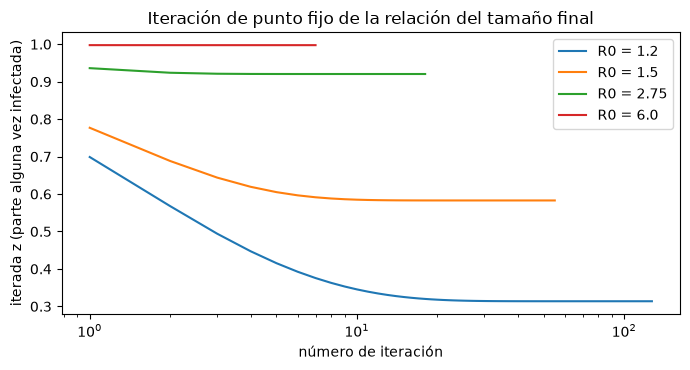

In [4]:
# dibuja las iteradas contra el número de iteración para los cuatro valores de R0
fig, ax = plt.subplots(figsize=(7, 3.8))
for value, trace in traces.items():
    ax.plot(range(1, len(trace) + 1), trace, label=f"R0 = {value}")
ax.set_xscale("log")
ax.set_xlabel("número de iteración")
ax.set_ylabel("iterada z (parte alguna vez infectada)")
ax.set_title("Iteración de punto fijo de la relación del tamaño final")
ax.legend()
fig.tight_layout()
plt.show()

Cada curva es una iteración, y todas bajan desde 1 hacia su propia respuesta. Para $R_0 = 6$ termina en 7 pasos; para $R_0 = 1{,}2$ toma 127, porque cerca del umbral la función $z \mapsto 1 - e^{-R_0 z}$ es casi tangente a la diagonal y las iteradas avanzan reptando. La figura usa un eje logarítmico para el número de iteración y así se ven ambos extremos. Todavía no dice nada del motor; la celda siguiente lo incorpora calculando la relación sobre una malla de $R_0$ y simulando cada caso con personas infectadas.

In [5]:
# Presentar el corte temporal y el límite infinito como cantidades distintas.
grid = np.linspace(0.5, 6.5, 121)
curve = [final_size(g) for g in grid]
points = {}
for case_id in CASES:
    p = params_of(case_id)
    if p.I0 == 0:
        continue
    run = simulate(p)
    r0_case = p.beta / p.gamma
    limit = final_size(r0_case, p.I0 / p.N)
    removed = run.R[-1] / p.N
    ever = (run.I[-1] + run.R[-1]) / p.N
    points[case_id] = (r0_case, removed)
    additional = run.I[-1] + run.R[-1] - p.I0
    print(f"{case_id}: R(T)/N={removed:.7f}, alguna vez={ever:.7f}, I(T)={run.I[-1]:.3f}")
    print(f"límite={limit:.7f}, removidos-menos-límite={removed-limit:+.7f}, adicionales={additional:.2f}")
    print(f"total infectado={ever*p.N:.2f}, inicial={p.I0:.0f}")

EX01_subcritical: R(T)/N=0.0017805, alguna vez=0.0017805, I(T)=0.001
límite=0.0017805, removidos-menos-límite=+0.0000000, adicionales=128.05
total infectado=178.05, inicial=50
EX02_epidemic: R(T)/N=0.9236543, alguna vez=0.9236543, I(T)=0.000
límite=0.9204875, removidos-menos-límite=+0.0031668, adicionales=92315.43
total infectado=92365.43, inicial=50
EX03_fast_burn: R(T)/N=0.9982142, alguna vez=0.9982142, I(T)=0.000
límite=0.9974861, removidos-menos-límite=+0.0007281, adicionales=99721.42
total infectado=99821.42, inicial=100
EX04_slow_spread: R(T)/N=0.2992847, alguna vez=0.3021744, I(T)=288.967
límite=0.3156283, removidos-menos-límite=-0.0163436, adicionales=30167.44
total infectado=30217.44, inicial=50


La celda siguiente dibuja la curva de la relación y ubica cada caso en ella según su $R_0$ y su fracción removida simulada.

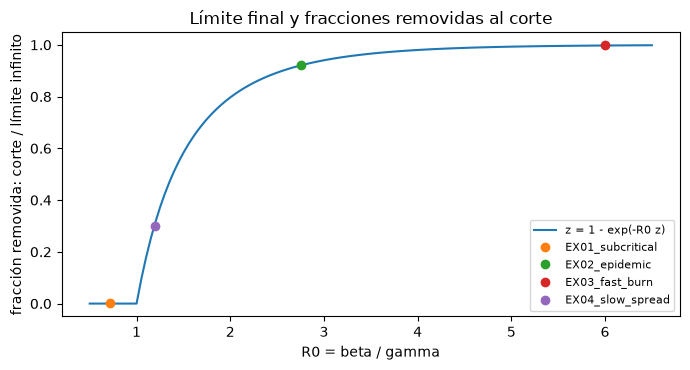

In [6]:
# dibuja la curva de la relación y ubica cada caso según su R0 y su fracción removida simulada
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(grid, curve, label="z = 1 - exp(-R0 z)")
for case_id, (r0_case, attack) in points.items():
    ax.plot([r0_case], [attack], "o", label=case_id)
ax.set_xlabel("R0 = beta / gamma")
ax.set_ylabel("fracción removida: corte / límite infinito")
ax.set_title("Límite final y fracciones removidas al corte")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La curva corresponde al límite de semilla despreciable; los puntos son R(T)/N de los casos finitos. El subcrítico termina con aproximadamente 0,0017805, unas 178 personas en total:50 iniciales y unas 128 adicionales, no solamente los contagios iniciales. Sus infectados terminales son despreciables a esta precisión. El caso epidémico excede su propio límite con semilla finita aproximadamente 0,0032; el rápido lo hace cerca de 0,0007. El caso lento queda por debajo porque todavía tiene unas 289 personas infectadas: R(T)/N≈0,2992847 frente a [I(T)+R(T)]/N≈0,3021744. El residuo numérico y la falta de resolución temporal son efectos distintos.

Ahora la afirmación de que el tiempo no importa. La celda corre el caso epidémico y un gemelo cuyas tasas de contacto y de recuperación se duplican, de modo que el brote corre al doble de velocidad y $R_0$ sigue siendo 2,75. Si la relación es correcta, el pico debería llegar casi el doble de temprano y las tasas de ataque deberían ser casi iguales.

In [7]:
# el caso epidémico y un gemelo al doble de velocidad, con el mismo R0 = 2,75
base = params_of("EX02_epidemic")
twin = replace(base, beta=2 * base.beta, gamma=2 * base.gamma)
runs = {"EX02_epidemic": simulate(base), "el doble de rápido": simulate(twin)}
for label, r in runs.items():
    print(f"{label:16s} pico {r.peak_I:7.0f}  el día {r.t_peak:6.2f}  fracción removida {r.attack_rate:.4f}")

EX02_epidemic    pico   27345  el día  24.25  fracción removida 0.9237
el doble de rápido pico   27836  el día  12.50  fracción removida 0.9269


La celda siguiente dibuja las personas infectadas de las dos corridas sobre los mismos ejes.

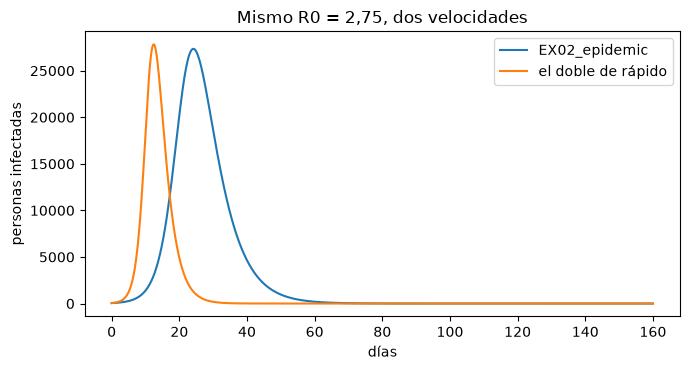

In [8]:
# dibuja las personas infectadas de las dos corridas sobre los mismos ejes
fig, ax = plt.subplots(figsize=(7, 3.8))
for label, r in runs.items():
    ax.plot(r.t, r.I, label=label)
ax.set_xlabel("días")
ax.set_ylabel("personas infectadas")
ax.set_title("Mismo R0 = 2,75, dos velocidades")
ax.legend()
fig.tight_layout()
plt.show()

El gemelo más rápido alcanza el pico el día 12,50 en vez de 24,25, comprimiendo aproximadamente la epidemia en el tiempo. Su fracción removida final es 0,9269 en lugar de 0,9237. Estos resultados de paso finito son próximos, pero no son límites continuos idénticos: el error Euler mayor con tasas más rápidas explica la diferencia. La figura muestra un pico anterior; no demuestra igualdad de áreas bajo las curvas infectadas. En el modelo continuo, dR/dt = gamma I implica que duplicar gamma conservando el total removido final reduce a la mitad la integral temporal de I. Igual carga final y personas-tiempo infectadas semejantes son afirmaciones distintas.

La relación tiene un segundo argumento, la parte inicial de infectados $i_0$, que las celdas anteriores dejaron en cero. La celda siguiente sube los primeros infectados a 5000 y a 20000 y compara tres números: la relación con $i_0$, la relación sin él, y el motor.

In [9]:
# sube los primeros infectados a 5000 y a 20000: la relación sigue al motor cuando se le da i0
for first in (50, 5000, 20000):
    q = replace(base, I0=first)
    z_i0 = final_size(2.75, first / base.N)
    print(f"I0 = {first:6d}  z(R0, i0) = {z_i0:.4f}  z(R0) = {final_size(2.75):.4f}", end="  ")
    print(f"simulada {simulate(q).attack_rate:.4f}")

I0 =     50  z(R0, i0) = 0.9205  z(R0) = 0.9204  simulada 0.9237
I0 =   5000  z(R0, i0) = 0.9254  z(R0) = 0.9204  simulada 0.9287
I0 =  20000  z(R0, i0) = 0.9396  z(R0) = 0.9204  simulada 0.9428


Con 20000 personas infectadas al inicio, una quinta parte del pueblo, la relación sin $i_0$ se equivoca en 0,019, mientras que la relación con $i_0$ queda a 0,0033 del motor en las tres filas. Esa diferencia constante es de nuevo el error de Euler, y dice que la relación, con su segundo argumento, describe lo que hace el motor. El último caso es la propagación lenta, cuya fracción removida quedó corta frente a la relación. La celda lo corre con su horizonte propio de 160 días y con 300 días.

In [10]:
# el caso de propagación lenta con su horizonte de 160 días y con 300 días, frente a la relación
slow = params_of("EX04_slow_spread")
z_slow = final_size(slow.beta / slow.gamma, slow.I0 / slow.N)
for horizon in (160, 300):
    r = simulate(replace(slow, days=horizon))
    print(f"horizonte = {horizon:3d}  fracción removida {r.attack_rate:.4f}  z = {z_slow:.4f}")

horizonte = 160  fracción removida 0.2993  z = 0.3156
horizonte = 300  fracción removida 0.3162  z = 0.3156


### Sensibilidad: un cambio pequeño del iterado no garantiza error pequeño

Escribe el mapa del oráculo como $F(z)=1-(1-i_0)\exp(-R_0z)$. En una solución convergida $z^*$ su factor local de contracción es

$$F'(z^*)=R_0(1-i_0)e^{-R_0z^*}=R_0(1-z^*).$$

La derivada es adimensional porque entrada y salida son fracciones. Cuando su magnitud queda muy por debajo de uno, el error restante disminuye rápido. Cerca del umbral se aproxima a uno y los iterados vecinos pueden diferir poco aun quedando una distancia apreciable hasta la solución. El oráculo detiene por diferencia entre iterados y devuelve el valor actual cuando agota su presupuesto; no retorna un objeto con estado de convergencia. Quien necesite un certificado debe examinar residuo y sensibilidad a un presupuesto mayor, en vez de considerar certificada cualquier salida numérica.

También hay una elección de rama. Con exactamente cero infecciones iniciales, el sistema temporal determinista permanece libre de enfermedad. Llamar al oráculo con `i0=0` y razón reproductiva superior a uno selecciona, en cambio, la rama positiva al comenzar desde uno; representa el tamaño límite condicionado a una pequeña semilla positiva, no un brote generado desde una ciudad sin infectados. Por eso se omite el control sin semilla al superponer resultados del motor sobre esa curva. Una semilla finita pequeña y su ausencia exacta responden preguntas distintas.

La firma del oráculo tampoco incluye inmunidad inicial. Supone susceptibles iguales a uno menos la fracción infectada, sin recuperados iniciales. Si existe inmunidad, transforma de forma coherente la población restante y la tasa efectiva, como en la lección del umbral, o emplea un modelo cuyo oráculo documentado incluya esa condición adicional. Insertar simplemente la razón reproductiva original conservaría una población susceptible incorrecta.

In [11]:
# Comparar presupuestos finitos cerca del umbral sin redefinir el oráculo.
for budget in (10, 100, 10000):
    candidate = final_size(1.001, tolerance=1e-12, max_iterations=budget)
    residual = abs(candidate - (1 - np.exp(-1.001 * candidate)))
    print(f"presupuesto={budget:5d}, z={candidate:.8f}, residual={residual:.3e}")

presupuesto=   10, z=0.15907786, residual=1.187e-02
presupuesto=  100, z=0.02034939, residual=1.857e-04
presupuesto=10000, z=0.00199743, residual=9.041e-11


### Úsalo con tus propios datos

Lee un registro `SIRParams` aceptado, calcula `r0=beta/gamma` e `i0=I0/N`, y llama a `final_size(r0, i0, tolerance=..., max_iterations=...)`. Ambos argumentos son adimensionales; entregar un número de infectados en vez de una fracción cambia la ecuación. Solicita `trace=[]` para diagnosticar convergencia lenta, sin almacenar trazas enormes innecesarias. `simulate(params, dt=...)` sigue siendo otra llamada, porque el oráculo no entrega fecha del pico, trayectoria ni predicción para un horizonte finito.

Antes de interpretar una discrepancia, examina infectados terminales y repite con un horizonte mayor y paso estable. Si quedan infecciones, `R(T)/N` excluye quienes siguen infectados en T y todavía no equivale a la fracción removida final. Después refina el paso para distinguir truncamiento temporal de sobreestimación numérica. La relación es exacta solamente dentro de las ecuaciones cerradas homogéneas y sus condiciones iniciales. No incorpora migración, susceptibilidad nueva, contacto variable o error observacional. Agregar esos mecanismos exige otro modelo gobernante, no una tolerancia menor. La sensibilidad presentada es numérica y condicional, sin intervalo estadístico.

## Resultados

**Respuesta:** Para R0=2,75 e I0=50 en 100000 personas, el límite final con semilla finita es 0,9205. El motor devuelve R(160)/N=0,9237, cerca de 0,0032 más alto por discretización; en este caso terminado I(160) es despreciable. El error no es universal: el rápido tiene una diferencia de alrededor de 0,0007 y el subcrítico una diferencia mucho menor. El subcrítico alcanza unas 178 infecciones totales, aproximadamente 128 además de sus 50 iniciales.

En el caso lento R(160)/N=0,2992847 y [I(160)+R(160)]/N=0,3021744: quedan unas 289 personas infectadas, por lo que no son la misma cantidad. El límite con sus condiciones iniciales es aproximadamente 0,3156, y a300 días la fracción removida llega a0,3162. El corte temporal y el error Euler deben examinarse por separado. Acelerar ambas tasas conserva el límite continuo con igual estado inicial, pero cambia la posición del pico y el error de un paso fijo. La relación no entrega una fecha ni justifica tratar toda salida heredada `attack_rate` como infectados acumulados al corte.

## Resumen

- La relación final describe el límite removido, equivalente a infectados totales solamente cuando I tiende a cero.
- El estado inicial finito y la rama elegida importan; ausencia exacta de semilla no equivale a semilla positiva pequeña.
- La magnitud del error Euler depende del caso y las tasas, no de un exceso universal de 0,003.
- El caso lento conserva infectados al día 160: R(T)/N no incluye a todos los infectados hasta T.
- Los límites de iteración y de horizonte exigen comprobaciones diferentes.

## Referencias

- Kermack, W. O. y McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- Miller, J. C. (2012). A note on the derivation of epidemic final sizes. Bulletin of Mathematical Biology. https://doi.org/10.1007/s11538-012-9749-6
- NumPy, https://pypi.org/project/numpy/ (fijado en `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (fijado en `notebooks/requirements.txt`).
- El motor y el oráculo de este repositorio, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`, `pipeline/oracles.py`).